In [48]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [49]:
#NBA API
url = "https://stats.nba.com/stats/leaguedashplayerstats"

headers = {
    'User-Agent': 'Mozilla/5.0 (Macintosh; Intel Mac OS X 10.15; rv:147.0) Gecko/20100101 Firefox/147.0',
    'Accept': '*/*',
    'Accept-Language': 'en-US,en;q=0.9',
    'Referer': 'https://www.nba.com/',
    'Origin': 'https://www.nba.com',
    'Connection': 'keep-alive',
    'Sec-Fetch-Dest': 'empty',
    'Sec-Fetch-Mode': 'cors',
    'Sec-Fetch-Site': 'same-site'
}

#Parameters

params = {
    'College': '',
    'Conference': '',
    'Country': '',
    'DateFrom': '',
    'DateTo': '',
    'Division': '',
    'DraftPick': '',
    'DraftYear': '',
    'GameScope': '',
    'GameSegment': '',
    'Height': '',
    'ISTRound': '',
    'LastNGames': '0',
    'LeagueID': '00',
    'Location': '',
    'MeasureType': 'Base',
    'Month': '0',
    'OpponentTeamID': '0',
    'Outcome': '',
    'PORound': '0',
    'PaceAdjust': 'N',
    'PerMode': 'PerGame',       # Changed from Totals to PerGame
    'Period': '0',
    'PlayerExperience': '',
    'PlayerPosition': '',
    'PlusMinus': 'N',
    'Rank': 'N',
    'Season': '2025-26',
    'SeasonSegment': '',
    'SeasonType': 'Regular Season',
    'ShotClockRange': '',
    'StarterBench': '',
    'TeamID': '0',
    'VsConference': '',
    'VsDivision': '',
    'Weight': ''
}

# Request data

response = requests.get(
    url,
    headers=headers,
    params=params,
    timeout=30
)

response.raise_for_status()

# Convert response to JSON

raw_data = response.json()

# Extract data

result = raw_data['resultSets'][0]
columns = result['headers']
rows = result['rowSet']

# Create DataFrame

df = pd.DataFrame(rows, columns=columns)

# Select columns shown on NBA website

selected_columns = [
    'PLAYER_NAME',
    'TEAM_ABBREVIATION',
    'AGE',
    'GP',
    'W',
    'L',
    'MIN',
    'PTS',
    'FGM',
    'FGA',
    'FG_PCT',
    'FG3M',
    'FG3A',
    'FG3_PCT',
    'FTM',
    'FTA',
    'FT_PCT',
    'OREB',
    'DREB',
    'REB',
    'AST',
    'TOV',
    'STL',
    'BLK',
    'PF',
    'NBA_FANTASY_PTS',
    'FP_HIGH_SCORE',
    'DD2',
    'TD3',
    'PLUS_MINUS'
]
df = df[selected_columns]

# Sort by PTS

df = df.sort_values(
    by='PTS',
    ascending=False
).reset_index(drop=True)

# Rename columns to match NBA website

df = df.rename(columns={
    'PLAYER_NAME': 'PLAYER',
    'TEAM_ABBREVIATION': 'TEAM',
    'FG_PCT': 'FG%',
    'FG3M': '3PM',
    'FG3A': '3PA',
    'FG3_PCT': '3P%',
    'FT_PCT': 'FT%',
    'NBA_FANTASY_PTS': 'TFP',
    'FP_HIGH_SCORE': 'HSFP',
    'PLUS_MINUS': '+/-'
})

# Convert percentages

for col in ['FG%', '3P%', 'FT%']:
    df[col] = (df[col] * 100).round(1)

# Check data

print("Number of players:", len(df))
print("Number of columns:", len(df.columns))
display(df.head(20))

# Save CSV

df.to_csv("nba_players_2025_26.csv", index=False)
print("Data saved successfully!")

Number of players: 582
Number of columns: 30


,PLAYER,TEAM,AGE,GP,W,L,MIN,PTS,FGM,FGA,...,AST,TOV,STL,BLK,PF,TFP,HSFP,DD2,TD3,+/-
0,Luka Dončić,LAL,27.0,64,43,21,35.8,33.5,10.8,22.8,...,8.3,4.0,1.6,0.5,2.4,57.7,64.3,34,8,2.9
1,Shai Gilgeous-Alexander,OKC,27.0,68,56,12,33.2,31.1,10.8,19.4,...,6.6,2.2,1.4,0.8,2.0,50.4,55.1,8,0,11.6
2,Anthony Edwards,MIN,24.0,61,37,24,35.0,28.8,9.9,20.2,...,3.7,2.9,1.4,0.8,1.9,43.9,47.7,2,0,2.7
3,Jaylen Brown,BOS,29.0,71,47,24,34.4,28.7,10.4,21.7,...,5.1,3.6,1.0,0.4,2.7,45.2,50.1,14,3,4.5
4,Tyrese Maxey,PHI,25.0,70,38,32,38.0,28.3,9.9,21.4,...,6.6,2.4,1.9,0.8,2.2,48.6,53.5,7,0,1.6
5,Kawhi Leonard,LAC,35.0,65,37,28,32.1,27.9,9.8,19.4,...,3.6,2.0,1.9,0.4,1.2,45.7,48.3,5,0,5.2
6,Donovan Mitchell,CLE,29.0,70,45,25,33.5,27.9,9.7,20.0,...,5.7,2.8,1.5,0.3,2.3,44.3,49.1,5,0,5.3
7,Nikola Jokić,DEN,31.0,65,43,22,34.8,27.7,9.9,17.4,...,10.7,3.7,1.4,0.8,2.7,62.1,68.7,55,34,8.5
8,Giannis Antetokounmpo,MIL,31.0,36,17,19,28.9,27.6,10.4,16.6,...,5.4,3.2,0.9,0.7,2.4,49.1,53.1,19,0,2.7
9,Joel Embiid,PHI,32.0,38,24,14,31.6,26.9,9.0,18.3,...,3.9,2.9,0.6,1.2,2.2,44.5,47.8,10,1,4.1


Data saved successfully!


In [50]:
nba = pd.read_csv("nba_players_2025_26.csv")
#Strip the spaces
nba.columns = nba.columns.str.strip()
nba['TEAM'] = nba['TEAM'].str.strip()


In [ ]:
#Check nulls
print(nba.isnull().sum())

In [53]:
#15 western teams
western_teams = [
    'DAL', 'DEN', 'GSW', 'HOU', 'LAC', 'LAL', 'MEM', 
    'MIN', 'NOP', 'OKC', 'PHX', 'POR', 'SAC', 'SAS', 'UTA'
]
west = nba[nba['TEAM'].isin(western_teams)]

team_names = {
    'DAL': 'Mavericks',
    'DEN': 'Nuggets',
    'GSW': 'Warriors',
    'HOU': 'Rockets',
    'LAC': 'Clippers',
    'LAL': 'Lakers',
    'MEM': 'Grizzlies',
    'MIN': 'Timberwolves',
    'NOP': 'Pelicans',
    'OKC': 'Thunder',
    'PHX': 'Suns',
    'POR': 'Blazers',
    'SAC': 'Kings',
    'SAS': 'Spurs',
    'UTA': 'Jazz'
}

west['TEAM'] = west['TEAM'].replace(team_names)

#Rename W to win
west = west.rename(columns={'W': 'Win'})


In [54]:
#Players need to at least played more than 40 games
west = west[west['GP'] >= 40]

#Sort team and min 
sorted_west = west.sort_values(by=['TEAM', 'MIN'], ascending=[True, False])
#Sorted based on the top 5 players most play time (min) in each team
top_5_players = sorted_west.groupby('TEAM').head(5)

#calculations
top_5_averages = top_5_players.groupby('TEAM').agg({
    'GP': 'max',
    'Win': 'max',  
    'MIN': 'mean',
    'PTS': 'mean',
    'REB': 'mean',
    'AST': 'mean',
    'FG%': 'mean'
}).round(1)

#Sorted based on most wins for the top 5 players of that team
final_sorted = top_5_averages.sort_values(by='Win', ascending=False)

#Add a rank 
final_sorted['Rank'] = range(1, len(final_sorted) + 1)
final_sorted = final_sorted[['Rank', 'Win', 'GP', 'PTS', 'REB', 'AST', 'FG%']]
print(final_sorted)


              Rank  Win  GP   PTS  REB  AST   FG%
TEAM                                             
Spurs            1   62  82  17.1  6.1  4.1  46.9
Thunder          2   61  77  15.7  4.6  3.1  48.2
Rockets          3   52  82  18.8  6.4  4.3  49.0
Timberwolves     4   49  82  17.6  6.3  3.4  51.5
Nuggets          5   48  75  18.4  6.2  5.0  50.8
Lakers           6   47  68  19.7  4.9  5.0  47.8
Suns             7   43  80  17.1  3.9  3.8  42.7
Blazers          8   42  82  18.7  4.9  4.0  45.2
Clippers         9   42  82  17.0  4.6  3.5  48.5
Warriors        10   37  82  14.6  4.1  3.6  43.8
Pelicans        11   26  82  16.7  4.8  3.1  46.8
Mavericks       12   25  77  14.6  5.1  2.9  45.8
Grizzlies       13   24  72  12.7  4.5  2.9  47.0
Kings           14   24  77  13.7  4.7  3.3  46.6
Jazz            15   19  72  18.9  6.2  3.4  47.1


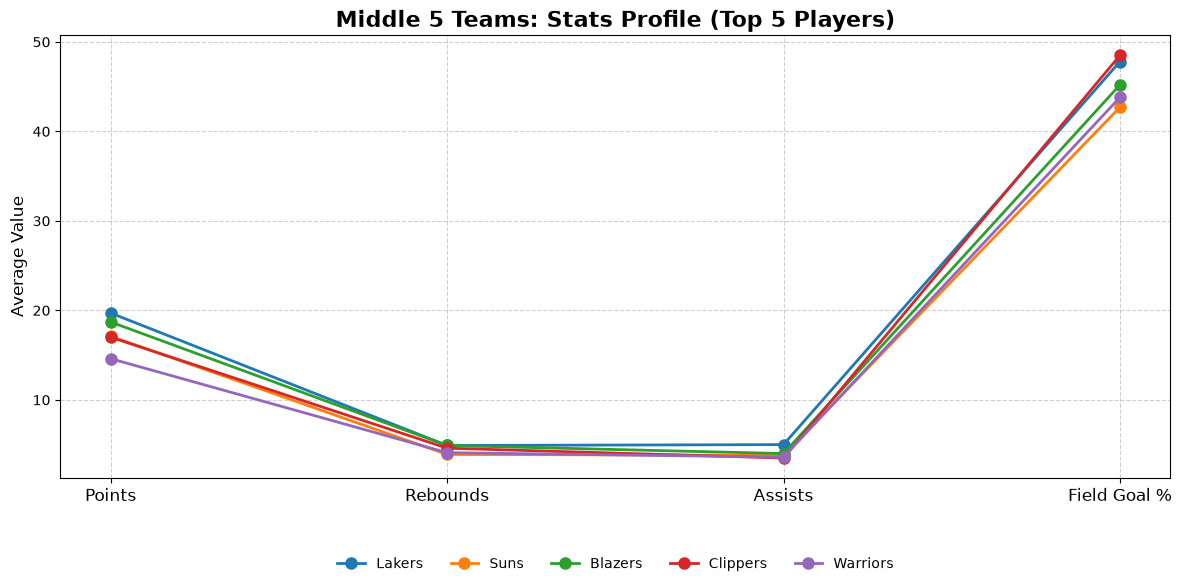

In [68]:
#Middle 5
middle_5 = final_sorted.iloc[5:10]
plt.figure(figsize=(12, 6))

# x-axis
stats = ['PTS', 'REB', 'AST', 'FG%']
stats_labels = ['Points', 'Rebounds', 'Assists', 'Field Goal %']

# Loop through each team in the middle 5 and plot their line
for team_name, row in middle_5.iterrows():
    # We grab the values for this specific team for the 4 stats
    values = row[stats].values
    plt.plot(stats, values, marker='o', markersize=8, linewidth=2, label=team_name)

#plot the labels
plt.xticks(ticks=stats, labels=stats_labels, fontsize=12)
plt.title('Middle 5 Teams: Stats Profile (Top 5 Players)', fontsize=16, fontweight='bold')
plt.ylabel('Average Value', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=5, frameon=False)
plt.tight_layout()
plt.show()
